# Монокулярная ORB VO (без замыкания петель)

In [1]:
from pathlib import Path
import csv
import json
import time

import cv2
import numpy as np
import matplotlib.pyplot as plt

ROOT = Path.cwd().parent if Path.cwd().name == 'scripts' else Path.cwd()
print('Project root:', ROOT)

IMAGE_DIR = ROOT / 'images'
TIMES_PATH = ROOT / 'calib' / 'times.txt'
CALIB_PATH = ROOT / 'calib' / 'camera_orb.yaml'
RESULTS_DIR = ROOT / 'results' / 'VO' / 'ORB'
RESULTS_DIR.mkdir(parents=True, exist_ok=True)
MONO_SCALE_CONSTANT = 1.0

plt.rcParams['figure.figsize'] = (16, 8)
plt.rcParams['font.family'] = 'serif'
plt.rcParams['font.serif'] = ['Times New Roman']
plt.rcParams['font.size'] = 18

Project root: /home/sadovetsrv/dev_KAMAZ/big_dataset


### Предобработка

После устранения дисторсии создаём постоянную маску: нулевые области соответствуют перилам и другим элементам конструкции. Маска покрывает трубы с небольшим запасом, но сохраняет дорогу и борта карьера.

In [2]:
image_paths = sorted(IMAGE_DIR.glob('*.png'))
timestamps = np.loadtxt(TIMES_PATH)

print(f'Frames: {len(image_paths)}')
print(f'Duration: {timestamps[-1] - timestamps[0]:.3f} s')
print(f'Mean frame rate: {(len(timestamps) - 1) / (timestamps[-1] - timestamps[0]):.3f} Hz')

Frames: 599
Duration: 59.899 s
Mean frame rate: 9.983 Hz


In [3]:
# FileStorage открывает YAML калибровки в режиме чтения.
storage = cv2.FileStorage(str(CALIB_PATH), cv2.FILE_STORAGE_READ)

# getNode(...).real() читает скалярные параметры модели.
fx = storage.getNode('Camera.fx').real()
fy = storage.getNode('Camera.fy').real()
cx = storage.getNode('Camera.cx').real()
cy = storage.getNode('Camera.cy').real()

# Аналогично читаем пять коэффициентов дисторсии и закрываем YAML-файл.
distortion = np.array([storage.getNode(name).real() for name in
                       ['Camera.k1', 'Camera.k2', 'Camera.p1', 'Camera.p2', 'Camera.k3']])
storage.release()

if min(fx, fy) <= 0:
    raise ValueError('Заполните fx, fy, cx, cy и дисторсию в calib/camera_orb.yaml')

K = np.array([[fx, 0, cx], [0, fy, cy], [0, 0, 1]], dtype=np.float64)

# imread загружает первый кадр в grayscale.
sample = cv2.imread(str(image_paths[0]), cv2.IMREAD_GRAYSCALE)
height, width = sample.shape

# initUndistortRectifyMap заранее вычисляет координаты источника для каждого выходного пикселя.
map_x, map_y = cv2.initUndistortRectifyMap(K, distortion, None, K, (width, height), cv2.CV_32FC1)

def load_gray(index):
    # Загружаем кадр по индексу в grayscale.
    gray = cv2.imread(str(image_paths[index]), cv2.IMREAD_GRAYSCALE)
    
    if gray is None:
        raise RuntimeError(f'Cannot read {image_paths[index]}')
    
    # remap применяет карты устранения дисторсии с билинейной интерполяцией яркости.
    return cv2.remap(gray, map_x, map_y, cv2.INTER_LINEAR)

print('K =\n', K)
print('Distortion =', distortion)

K =
 [[525.   0. 640.]
 [  0. 315. 360.]
 [  0.   0.   1.]]
Distortion = [0. 0. 0. 0. 0.]


Исключено маской: 219127 из 921600 пикселей (23.78%)
Осталось для ORB: 76.22% кадра


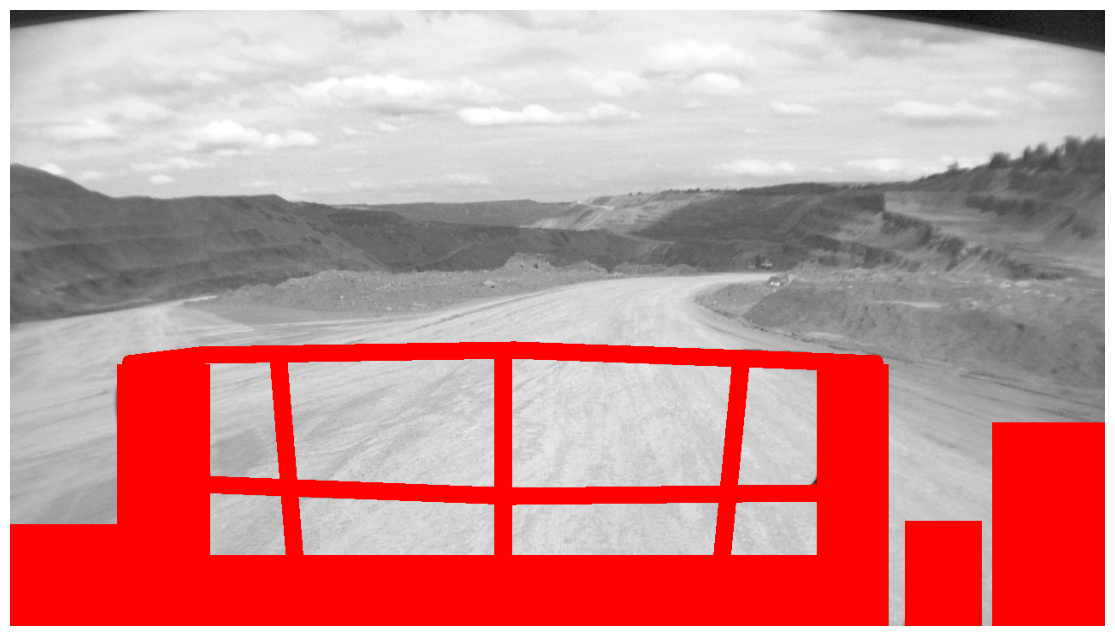

In [28]:
# Белый (255) — область поиска ORB, чёрный (0) — исключённая область.
feature_mask = np.full((height, width), 255, dtype=np.uint8)

# ЛИНИИ
# Точка (x, y) задаётся долями ширины и высоты: 
# (0, 0) — левый верхний угол, (1, 1) — правый нижний.
RAIL_POLYLINES = [
    # Верхняя горизонтальная труба и её изгибы.
    [(0.110, 0.575), (0.175, 0.560), (0.460, 0.552),
     (0.670, 0.566), (0.790, 0.575)],
    
    # Далее каждый список описывает отдельную стойку или фрагмент перил.
    [(0.245, 0.560), (0.260, 0.900)],
    [(0.450, 0.560), (0.450, 0.900)],
    [(0.668, 0.570), (0.650, 0.900)],
    
    [(0.175, 0.770), (0.460, 0.790), (0.735, 0.785)],
]

# ПРЯМОУГОЛЬНИКИ. Формат: (x_лево, y_верх, x_право, y_низ).
# Вся внутренняя область закрашивается нулём и исключается из детекции.
STATIC_RECTANGLES = [
    (0.000, 0.840, 0.100, 1.000),  # Перила в левой нижней части кадра.
    (0.100, 0.580, 0.180, 1.000),  # Перила слева "вверх".
    (0.120, 0.890, 0.800, 1.000),  # Нижняя площадка.
    (0.740, 0.580, 0.800, 1.000),  # Перила справа "вверх".
    (0.820, 0.835, 0.885, 1.000),  # Перила справа "между".
    (0.900, 0.675, 1.000, 1.000),  # Перила в правой нижней части кадра.
]

# Толщина линий и дополнительный запас вокруг ВСЕХ исключённых фигур, в пикселях.
# Если ORB всё ещё находит точки рядом с перилами, сначала увеличь MASK_MARGIN_PX.
RAIL_THICKNESS_PX = max(5, round(min(height, width) * 0.02))
MASK_MARGIN_PX = 3

def normalized_to_pixel(point):
    x, y = point
    return round(x * (width - 1)), round(y * (height - 1))

for polyline in RAIL_POLYLINES:
    points = np.array([normalized_to_pixel(point) for point in polyline], dtype=np.int32)
    
    # OpenCV рисует ломаную чёрным цветом (0), то есть помечает её как запрещённую.
    cv2.polylines(feature_mask, [points], False, 0, RAIL_THICKNESS_PX, cv2.LINE_AA)

for x1, y1, x2, y2 in STATIC_RECTANGLES:
    # thickness=-1 в cv2.rectangle означает закрашенный прямоугольник, а не только рамку.
    cv2.rectangle(feature_mask, normalized_to_pixel((x1, y1)),
                  normalized_to_pixel((x2, y2)), 0, thickness=-1)

# Расширяем чёрные области на MASK_MARGIN_PX во все стороны.
excluded_mask = 255 - feature_mask
if MASK_MARGIN_PX > 0:
    kernel_size = 2 * MASK_MARGIN_PX + 1
    
    # Морфологическая дилатация OpenCV расширяет ненулевые области excluded_mask.
    excluded_mask = cv2.dilate(excluded_mask, np.ones((kernel_size, kernel_size), np.uint8))
    
feature_mask = 255 - excluded_mask

# Считаем площадь именно итоговой маски: после объединения фигур и дилатации.
excluded_pixels = np.count_nonzero(feature_mask == 0)
excluded_percent = 100.0 * excluded_pixels / feature_mask.size
print(f'Исключено маской: {excluded_pixels} из {feature_mask.size} пикселей ({excluded_percent:.2f}%)')
print(f'Осталось для ORB: {100.0 - excluded_percent:.2f}% кадра')

# cvtColor преобразует grayscale в RGB, чтобы красным показать исключённые области.
mask_preview = cv2.cvtColor(load_gray(0), cv2.COLOR_GRAY2RGB)
mask_preview[feature_mask == 0] = (255, 0, 0)

figure = plt.figure()
plt.imshow(mask_preview)
plt.axis('off')
figure.savefig(RESULTS_DIR / 'orb_preprocessing_mask.png', dpi=200, bbox_inches='tight')

## 1. Feature Detection

ORB состоит из двух частей: **детектор** находит устойчивые ключевые точки, а **дескриптор** описывает изображение вокруг каждой точки. Детектор работает на пирамиде масштабов, поэтому одна и та же структура может находиться при разном размере в кадре.

- центр круга — координата ключевой точки;
- радиус круга — размер её характерной окрестности (`KeyPoint.size`), связанный с масштабом пирамиды; 
- радиус с радиальной линией — масштаб и главная ориентация точки; линия показывает направление, вычисленное по распределению яркости в окрестности.

Для каждой точки ORB вычисляет **256-битный бинарный дескриптор** (32 байта). Это результаты 256 попарных сравнений яркости в заданном шаблоне вокруг точки, повёрнутом на её главный угол. Два дескриптора сравниваются расстоянием Хэмминга — числом различающихся битов: 0 означает полное совпадение, а большее значение — менее похожие окрестности.

Detected keypoints: 902
Descriptor matrix: (902, 32) uint8


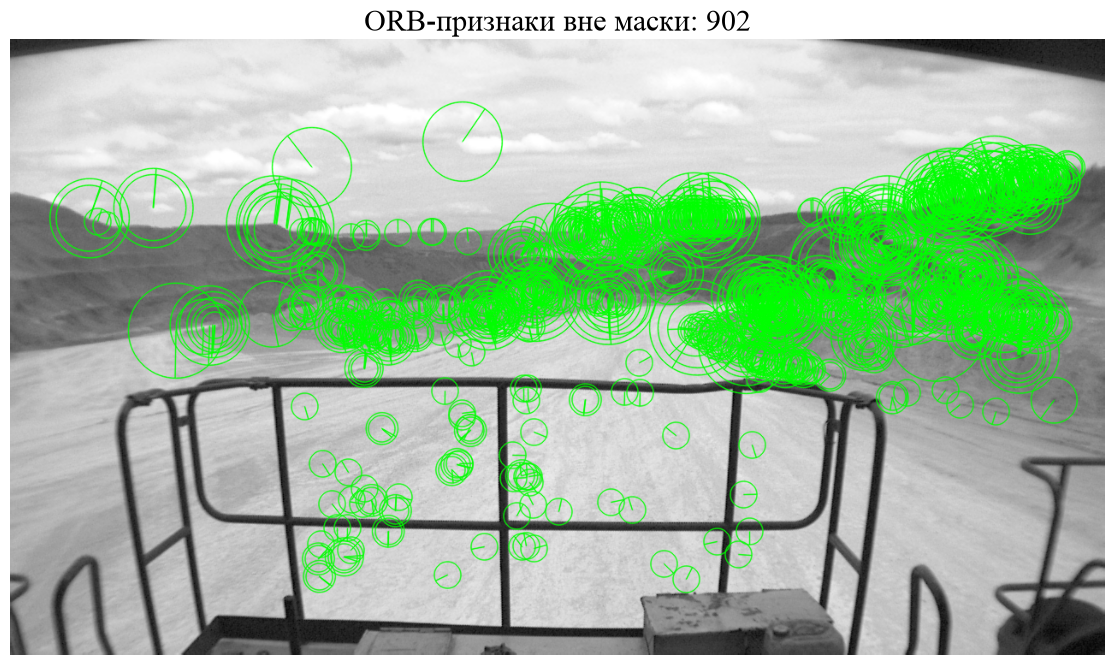

In [29]:
# ORB_create создаёт детектор+дескриптор: до 2000 точек, 8 уровней пирамиды,
# коэффициент уменьшения изображения 1.2 и порог FAST-детектора 20.
orb = cv2.ORB_create(nfeatures=2000, scaleFactor=1.2, nlevels=8, fastThreshold=20)

gray0 = load_gray(0)

# detectAndCompute возвращает ключевые точки и матрицу N×32 типа uint8:
# одна строка = один 256-битный дескриптор. feature_mask запрещает поиск в нулевых зонах.
keypoints0, descriptors0 = orb.detectAndCompute(gray0, feature_mask)
print('Detected keypoints:', len(keypoints0))
print('Descriptor matrix:', descriptors0.shape, descriptors0.dtype)

# drawKeypoints с DRAW_RICH_KEYPOINTS рисует масштаб кругом и ориентацию линией.
feature_image = cv2.drawKeypoints(gray0, keypoints0, None, color=(0, 255, 0),
                                  flags=cv2.DRAW_MATCHES_FLAGS_DRAW_RICH_KEYPOINTS)

figure = plt.figure()
plt.imshow(feature_image)
plt.title(f'ORB-признаки вне маски: {len(keypoints0)}')
plt.axis('off')
figure.savefig(RESULTS_DIR / 'orb_feature_detection.png', dpi=200, bbox_inches='tight')

# Обёртка используется в последовательном трекинге; point_ids связывает 2D-точки с картой.
def detect_frame(index):
    gray = load_gray(index)
    keypoints, descriptors = orb.detectAndCompute(gray, feature_mask)
    return {'index': index, 'gray': gray, 'keypoints': keypoints,
            'descriptors': descriptors, 'point_ids': np.full(len(keypoints), -1, dtype=np.int64),
            'pose': None}

frame0 = {'index': 0, 'gray': gray0, 'keypoints': keypoints0, 'descriptors': descriptors0,
          'point_ids': np.full(len(keypoints0), -1, dtype=np.int64), 'pose': np.eye(4)}

## 2. Feature Tracking

Feature Tracking - **сопоставление дескрипторов между двумя кадрами**.

1. `BFMatcher(NORM_HAMMING)` перебирает пары дескрипторов и сравнивает их по числу различающихся битов.
2. `knnMatch(..., k=2)` возвращает двух ближайших кандидатов для каждого дескриптора.
3. **Ratio test:** лучший кандидат принимается только при `best.distance < 0.75 × second_best.distance`. Если оба кандидата почти одинаково похожи, выбор неоднозначен и пара отбрасывается.
4. Поиск повторяется в обратную сторону. **Mutual check** оставляет пару A→B только если обратный поиск даёт B→A.
5. В `DMatch` поля `queryIdx` и `trainIdx` — индексы точек первого и второго кадра. По ним далее формируются пары пиксельных координат.

Keypoints: 902 → 1025
Mutual ratio-test matches: 244
Matches / frame-0 keypoints: 27.1%


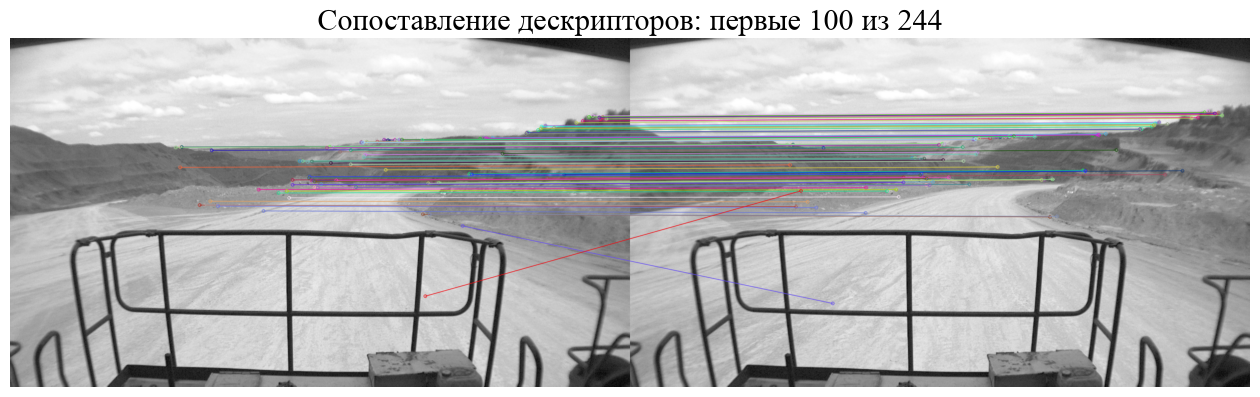

In [30]:
def match_descriptors(query, train, ratio=0.75):
    
    # BFMatcher выполняет полный перебор; NORM_HAMMING выбран для бинарных ORB-дескрипторов.
    matcher = cv2.BFMatcher(cv2.NORM_HAMMING)
    # Для каждого дескриптора knnMatch возвращает два ближайших соседа (k=2).
    forward = matcher.knnMatch(query, train, k=2)
    backward = matcher.knnMatch(train, query, k=2)
    # Ratio test отбрасывает пары, у которых второй кандидат слишком похож на лучший.
    forward_good = [pair[0] for pair in forward if len(pair) == 2 and pair[0].distance < ratio * pair[1].distance]
    backward_good = [pair[0] for pair in backward if len(pair) == 2 and pair[0].distance < ratio * pair[1].distance]
    # Взаимная проверка: индексы должны образовывать пару в обоих направлениях.
    reverse = {match.queryIdx: match.trainIdx for match in backward_good}
    
    return [match for match in forward_good if reverse.get(match.trainIdx) == match.queryIdx]

INIT_FRAME_INDEX = 10
TRACK_FRAME_INDEX = INIT_FRAME_INDEX + 1
gray1 = load_gray(INIT_FRAME_INDEX)

# Повторяем детекцию ORB на новом кадре с той же маской предобработки.
keypoints1, descriptors1 = orb.detectAndCompute(gray1, feature_mask)
matches = match_descriptors(descriptors0, descriptors1)

print(f'Keypoints: {len(keypoints0)} → {len(keypoints1)}')
print(f'Mutual ratio-test matches: {len(matches)}')
print(f'Matches / frame-0 keypoints: {len(matches) / max(len(keypoints0), 1):.1%}')

# drawMatches соединяет сопоставленные точки; одиночные точки скрыты для читаемости.
match_image = cv2.drawMatches(gray0, keypoints0, gray1, keypoints1, matches[:100], None,
                              flags=cv2.DrawMatchesFlags_NOT_DRAW_SINGLE_POINTS)

figure = plt.figure()
plt.imshow(match_image)
plt.title(f'Сопоставление дескрипторов: первые 100 из {len(matches)}')
plt.axis('off')
figure.savefig(RESULTS_DIR / 'orb_feature_tracking.png', dpi=200, bbox_inches='tight')

frame1 = {'index': INIT_FRAME_INDEX, 'gray': gray1, 'keypoints': keypoints1,
          'descriptors': descriptors1, 'point_ids': np.full(len(keypoints1), -1, dtype=np.int64),
          'pose': None}
initialization_matches = matches

## 3. Motion Estimation

Из массива `matches` берём пары пиксельных координат `points0` и `points1`. По ним нужно найти относительное движение камеры, но часть соответствий всё ещё ошибочна.

**Essential matrix и RANSAC:**

1. Матрица `E` связывает лучи двух камер эпиполярным условием: соответствующая точка должна лежать около эпиполярной линии. Калибровка `K` переводит пиксели в нормированные координаты.
2. RANSAC многократно выбирает небольшую случайную группу соответствий, строит по ней кандидата `E` и проверяет остальные пары.
3. Пары с эпиполярной ошибкой не более `threshold=1.0` пикселя получают значение 1 в `essential_mask` — это **inliers**. Остальные — **outliers**. Ниже они показаны зелёным и красным соответственно.
`prob=0.999` задаёт желаемую вероятность найти согласованную модель; это не процент inliers.

**Восстановление позы:** `recoverPose` разлагает `E` на поворот `R` и направление перевода `t`, затем проверяет гипотезы через положительную глубину точек перед обеими камерами. `pose_mask` может содержать меньше точек, чем `essential_mask`, поскольку эпиполярный inlier не обязан иметь физически корректную глубину.

Длина `t` нормирована: монокулярная пара кадров даёт направление перевода, но не метры без внешнего масштаба. 

Essential inliers: 188/244 (77.0%)
Positive-depth pose inliers: 134
Rotation: 1.687 deg
Unit-scale translation direction: [-0.25294269 -0.03073112 -0.96699307]
ВЫВОД: зелёные соответствия согласуются с одной эпиполярной геометрией; красные отброшены RANSAC.


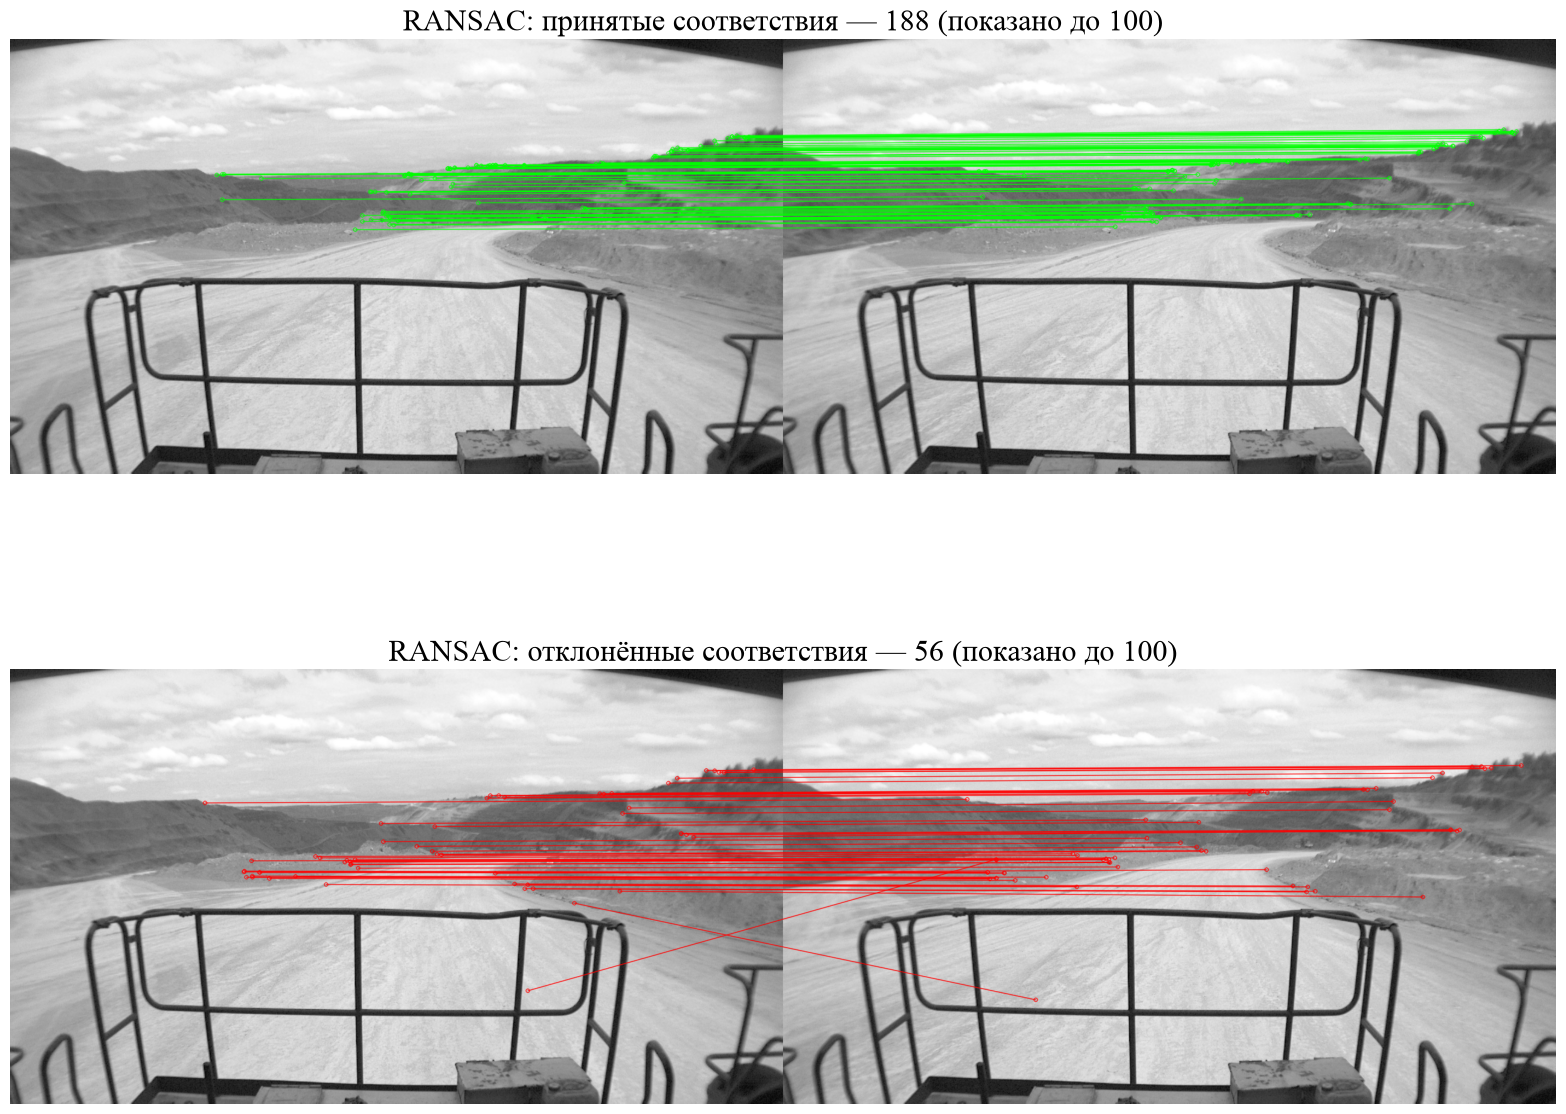

In [32]:
# Индексы DMatch превращаем в два массива пиксельных координат shape (N, 2).
points0 = np.float32([keypoints0[m.queryIdx].pt for m in matches])
points1 = np.float32([keypoints1[m.trainIdx].pt for m in matches])

# findEssentialMat оценивает E методом RANSAC; threshold — эпиполярный порог в пикселях.
# essential_mask — бинарный вектор: 1 для inliers, 0 для outliers.
E, essential_mask = cv2.findEssentialMat(points0, points1, K, method=cv2.RANSAC,
                                         prob=0.999, threshold=1.0)

if E is None or E.shape != (3, 3):
    raise RuntimeError('Essential matrix estimation failed')

# recoverPose получает R и единичный вектор t из E, проверяя положительную глубину точек.
_, R, t, pose_mask = cv2.recoverPose(E, points0, points1, K, mask=essential_mask.copy())

essential_inliers = int(essential_mask.sum())
pose_inliers = int(pose_mask.sum())

if pose_inliers < 20:
    raise RuntimeError('Мало точек с положительной глубиной: увеличьте INIT_FRAME_INDEX для большего параллакса')

# Мировая система совпадает с камерой кадра 0. Поза кадра 10 — преобразование world→camera.
# Масштаб 1.0 задаёт условную единицу длины всей монокулярной карты, а не метры.
frame0['pose'] = np.eye(4)
frame1['pose'] = np.eye(4)
frame1['pose'][:3, :3] = R
frame1['pose'][:3, 3] = MONO_SCALE_CONSTANT * t.ravel()

# Угол поворота получаем из следа ортогональной матрицы R: trace(R)=1+2cos(theta).
rotation_deg = np.degrees(np.arccos(np.clip((np.trace(R) - 1) / 2, -1, 1)))

print(f'Essential inliers: {essential_inliers}/{len(matches)} ({essential_inliers / len(matches):.1%})')
print(f'Positive-depth pose inliers: {pose_inliers}')
print(f'Rotation: {rotation_deg:.3f} deg')
print('Unit-scale translation direction:', t.ravel())
print('ВЫВОД: зелёные соответствия согласуются с одной эпиполярной геометрией; красные отброшены RANSAC.')

# Разделяем исходные DMatch по маске RANSAC, сохраняя соответствие индексов.
is_ransac_inlier = essential_mask.ravel() > 0
inlier_matches = [match for match, keep in zip(matches, is_ransac_inlier) if keep]
outlier_matches = [match for match, keep in zip(matches, is_ransac_inlier) if not keep]

# drawMatches рисует центры точек и соединяющие линии. Зелёный — принято, красный — отклонено.
ransac_inlier_image = cv2.drawMatches(
    gray0, keypoints0, gray1, keypoints1, inlier_matches[:100], None,
    matchColor=(0, 255, 0), singlePointColor=(0, 255, 0),
    flags=cv2.DrawMatchesFlags_NOT_DRAW_SINGLE_POINTS)
ransac_outlier_image = cv2.drawMatches(
    gray0, keypoints0, gray1, keypoints1, outlier_matches[:100], None,
    matchColor=(255, 0, 0), singlePointColor=(255, 0, 0),
    flags=cv2.DrawMatchesFlags_NOT_DRAW_SINGLE_POINTS)

fig, axes = plt.subplots(2, 1, figsize=(16, 14))

axes[0].imshow(ransac_inlier_image)
axes[0].set_title(f'RANSAC: принятые соответствия — {len(inlier_matches)} (показано до 100)')
axes[0].axis('off')

axes[1].imshow(ransac_outlier_image)
axes[1].set_title(f'RANSAC: отклонённые соответствия — {len(outlier_matches)} (показано до 100)')
axes[1].axis('off')

fig.tight_layout()
fig.savefig(RESULTS_DIR / 'orb_ransac.png', dpi=200, bbox_inches='tight')

## 4. Triangulation

Пересекаем лучи соответствующих пикселей и создаём начальную 3D-карту. Оставляем только пары с положительной глубиной в обеих камерах, ошибкой репроекции менее 2 пикселей и параллаксом более 0,2°. Параллакс — угол между лучами из двух центров камеры: при почти нулевом смещении глубина численно нестабильна.

Ошибка репроекции показывает согласованность 3D-точки с двумя изображениями, но не определяет абсолютный масштаб. В дальнейшем функция пополняет карту только точками, которые ещё не имеют идентификатора `point_id`.

In [33]:
map_points = []
map_descriptors = []

def triangulate_new(reference, current, matches):
    # Новыми кандидатами считаем только соответствия, ещё не связанные с 3D-точкой.
    candidates = [m for m in matches
                  if reference['point_ids'][m.queryIdx] < 0 and current['point_ids'][m.trainIdx] < 0]
    if len(candidates) < 8:
        return {'new_points': 0, 'median_reprojection_px': np.nan, 'candidates': len(candidates)}

    ref_px = np.float32([reference['keypoints'][m.queryIdx].pt for m in candidates])
    cur_px = np.float32([current['keypoints'][m.trainIdx].pt for m in candidates])
    P_ref = K @ reference['pose'][:3, :]
    P_cur = K @ current['pose'][:3, :]

    # triangulatePoints пересекает лучи и возвращает однородные 3D-координаты 4×N.
    homogeneous = cv2.triangulatePoints(P_ref, P_cur, ref_px.T, cur_px.T)
    xyz_ref = (homogeneous[:3] / homogeneous[3]).T
    xyz_cur = (current['pose'][:3, :3] @
               (reference['pose'][:3, :3].T @ (xyz_ref - reference['pose'][:3, 3]).T +
                current['pose'][:3, 3:4])).T
    finite = np.isfinite(xyz_ref).all(axis=1)
    positive = finite & (xyz_ref[:, 2] > 0) & (xyz_cur[:, 2] > 0)
    error = np.full(len(candidates), np.inf)
    parallax = np.zeros(len(candidates))
    C_ref = -reference['pose'][:3, :3].T @ reference['pose'][:3, 3]
    C_cur = -current['pose'][:3, :3].T @ current['pose'][:3, 3]

    for point_index in np.flatnonzero(positive):
        # Проецируем 3D-точку обратно и измеряем среднюю ошибку в пикселях.
        proj_ref = K @ xyz_ref[point_index]
        proj_cur = K @ xyz_cur[point_index]
        uv_ref = proj_ref[:2] / proj_ref[2]
        uv_cur = proj_cur[:2] / proj_cur[2]
        error[point_index] = 0.5 * (np.linalg.norm(uv_ref - ref_px[point_index]) +
                                    np.linalg.norm(uv_cur - cur_px[point_index]))
        world_xyz = reference['pose'][:3, :3].T @ (xyz_ref[point_index] - reference['pose'][:3, 3])
        ray_ref = world_xyz - C_ref
        ray_cur = world_xyz - C_cur
        cosine = np.dot(ray_ref, ray_cur) / (np.linalg.norm(ray_ref) * np.linalg.norm(ray_cur))
        parallax[point_index] = np.degrees(np.arccos(np.clip(cosine, -1, 1)))

    valid = positive & (error < 2.0) & (parallax > 0.2)
    for match, xyz, keep in zip(candidates, xyz_ref, valid):
        if not keep:
            continue
        point_id = len(map_points)
        map_points.append(xyz.copy())
        map_descriptors.append(current['descriptors'][match.trainIdx].copy())
        reference['point_ids'][match.queryIdx] = point_id
        current['point_ids'][match.trainIdx] = point_id

    return {'new_points': int(valid.sum()),
            'median_reprojection_px': float(np.median(error[valid])) if valid.any() else np.nan,
            'candidates': len(candidates)}

initialization_triangulation = triangulate_new(frame0, frame1, initialization_matches)
print(initialization_triangulation)
print('Initial map size:', len(map_points))
if len(map_points) < 20:
    raise RuntimeError('Insufficient initial map')
print('ВЫВОД: на выходе получены 3D-координаты в условном масштабе и связи point_id с 2D-признаками.')

{'new_points': 208, 'median_reprojection_px': 0.5508450874873538, 'candidates': 244}
Initial map size: 208
ВЫВОД: на выходе получены 3D-координаты в условном масштабе и связи point_id с 2D-признаками.


## 5. Map Tracking

После появления карты основной трекинг оценивает позу по соответствиям **3D map point → 2D keypoint**. `solvePnPRansac` отбрасывает часть ошибочных совпадений, а уточнение Левенберга—Марквардта выполняется только по принятым соответствиям. Поза хранится как `T_cw` (мир → камера); центр камеры вычисляется как `C = -R.T @ t`.

Ключевой кадр добавляется при снижении числа отслеженных точек или после 8 кадров. Между старым и новым ключевыми кадрами триангулируются новые точки. На выходе получаем **траекторию центров камеры для всей последовательности**, а не одну позу. В оригинальном ORB-SLAM2 дополнительно есть covisibility graph, culling и локальная bundle adjustment; здесь они не реализованы.

In [34]:
def track_frame(reference, current):
    matches = match_descriptors(reference['descriptors'], current['descriptors'])
    candidates = [m for m in matches if reference['point_ids'][m.queryIdx] >= 0]
    result = {'matches': len(matches), '2d3d_candidates': len(candidates),
              'pnp_inliers': 0, 'relocalized': 0, 'success': False}
    if len(candidates) < 6:
        return result, matches

    object_points = np.float32([map_points[reference['point_ids'][m.queryIdx]] for m in candidates])
    image_points = np.float32([current['keypoints'][m.trainIdx].pt for m in candidates])

    # solvePnPRansac оценивает world→camera по 3D→2D парам и отбрасывает ошибки репроекции >2 px.
    success, rvec, tvec, inliers = cv2.solvePnPRansac(
        object_points, image_points, K, None, iterationsCount=1000,
        reprojectionError=2.0, confidence=0.999, flags=cv2.SOLVEPNP_ITERATIVE)
    if not success or inliers is None or len(inliers) < 6:
        return result, matches

    indices = inliers.ravel()
    # solvePnPRefineLM уточняет rvec/tvec только по inliers методом Левенберга—Марквардта.
    rvec, tvec = cv2.solvePnPRefineLM(object_points[indices], image_points[indices], K, None, rvec, tvec)
    # Rodrigues преобразует вектор вращения в матрицу 3×3.
    R_cw, _ = cv2.Rodrigues(rvec)
    current['pose'] = np.eye(4)
    current['pose'][:3, :3] = R_cw
    current['pose'][:3, 3] = tvec.ravel()
    for index in indices:
        match = candidates[index]
        current['point_ids'][match.trainIdx] = reference['point_ids'][match.queryIdx]

    # projectPoints проецирует 3D-inliers обратно в изображение для контроля ошибки.
    projected, _ = cv2.projectPoints(object_points[indices], rvec, tvec, K, None)
    reprojection = np.linalg.norm(projected.reshape(-1, 2) - image_points[indices], axis=1)
    result.update(success=True, pnp_inliers=len(indices),
                  median_reprojection_px=float(np.median(reprojection)))
    return result, matches

demo_frame = detect_frame(INIT_FRAME_INDEX + 1)
demo_result, _ = track_frame(frame1, demo_frame)
print('Демонстрация одного PnP-кадра:', demo_result)
print('Центр камеры:', (-demo_frame['pose'][:3, :3].T @ demo_frame['pose'][:3, 3]).ravel())

reference = frame1
# Несколько последних ключевых кадров нужны для восстановления после локальной потери трекинга.
keyframe_history = [frame0, frame1]
successful_poses = {0: frame0['pose'].copy(), INIT_FRAME_INDEX: frame1['pose'].copy()}
keyframe_indices = [0, INIT_FRAME_INDEX]
diagnostics = [
    {'frame': 0, 'timestamp': timestamps[0], 'keypoints': len(frame0['keypoints']), 'matches': 0,
     '2d3d_candidates': 0, 'pnp_inliers': 0, 'median_reprojection_px': np.nan,
     'new_map_points': 0, 'keyframe': 1, 'relocalized': 0, 'runtime_s': 0.0,
     'status': 'initialization_origin'},
    {'frame': INIT_FRAME_INDEX, 'timestamp': timestamps[INIT_FRAME_INDEX],
     'keypoints': len(frame1['keypoints']), 'matches': len(initialization_matches),
     '2d3d_candidates': 0, 'pnp_inliers': int(pose_mask.sum()),
     'median_reprojection_px': initialization_triangulation['median_reprojection_px'],
     'new_map_points': initialization_triangulation['new_points'], 'keyframe': 1,
     'relocalized': 0, 'runtime_s': 0.0, 'status': 'initialized'},
]

for frame_index in range(INIT_FRAME_INDEX + 1, len(image_paths)):
    started = time.perf_counter()
    current = detect_frame(frame_index)
    result, matches = track_frame(reference, current)
    tracking_reference = reference
    # Если опорный кадр устарел, пробуем до 7 предыдущих ключевых кадров той же карты.
    # Это локальное восстановление трекинга, а не loop closure и не новая инициализация масштаба.
    if not result['success']:
        for candidate_reference in reversed(keyframe_history[:-1]):
            candidate_result, candidate_matches = track_frame(candidate_reference, current)
            if candidate_result['success']:
                result, matches = candidate_result, candidate_matches
                result['relocalized'] = 1
                tracking_reference = candidate_reference
                break
    new_points = 0
    is_keyframe = False
    if result['success']:
        successful_poses[frame_index] = current['pose'].copy()
        reference = tracking_reference
        elapsed = frame_index - reference['index']
        reference_tracks = max(1, int(np.sum(reference['point_ids'] >= 0)))
        if elapsed >= 3 and (elapsed >= 8 or result['pnp_inliers'] < 0.70 * reference_tracks
                             or result['pnp_inliers'] < 50):
            triangulation = triangulate_new(reference, current, matches)
            new_points = triangulation['new_points']
            reference = current
            keyframe_history.append(current)
            keyframe_indices.append(frame_index)
            is_keyframe = True
    status = 'tracked' if result['success'] else 'lost'
    diagnostics.append({'frame': frame_index, 'timestamp': timestamps[frame_index],
                        'keypoints': len(current['keypoints']), 'matches': result['matches'],
                        '2d3d_candidates': result['2d3d_candidates'],
                        'pnp_inliers': result['pnp_inliers'],
                        'median_reprojection_px': result.get('median_reprojection_px', np.nan),
                        'new_map_points': new_points, 'keyframe': int(is_keyframe),
                        'relocalized': result['relocalized'], 'runtime_s': time.perf_counter() - started, 'status': status})
    if frame_index % 50 == 0 or not result['success']:
        print(f'Frame {frame_index}: {status}, PnP={result["pnp_inliers"]}, '
              f'map={len(map_points)}, keyframes={len(keyframe_indices)}')

lost_frames = [row['frame'] for row in diagnostics if row['status'] == 'lost']
print(f'Tracked: {len(successful_poses)}/{len(image_paths)}; lost: {len(lost_frames)}')
print(f'Keyframes: {len(keyframe_indices)}; map points: {len(map_points)}')
print('ВЫВОД: Map Tracking дал последовательность поз; потерянные кадры оставлены без позы, без интерполяции.')

Демонстрация одного PnP-кадра: {'matches': 517, '2d3d_candidates': 149, 'pnp_inliers': 136, 'relocalized': 0, 'success': True, 'median_reprojection_px': 0.7795702219009399}
Центр камеры: [ 0.29903569 -0.03590373  1.01677236]
Frame 50: tracked, PnP=8, map=208, keyframes=18
Frame 100: tracked, PnP=7, map=208, keyframes=54
Frame 144: lost, PnP=0, map=208, keyframes=86
Frame 145: lost, PnP=0, map=208, keyframes=86
Frame 150: tracked, PnP=6, map=208, keyframes=90
Frame 165: lost, PnP=0, map=208, keyframes=100
Frame 169: lost, PnP=0, map=208, keyframes=102
Frame 171: lost, PnP=0, map=208, keyframes=102
Frame 172: lost, PnP=0, map=208, keyframes=102
Frame 179: lost, PnP=0, map=208, keyframes=108
Frame 183: lost, PnP=0, map=208, keyframes=110
Frame 188: lost, PnP=0, map=208, keyframes=114
Frame 190: lost, PnP=0, map=208, keyframes=115
Frame 192: lost, PnP=0, map=208, keyframes=116
Frame 193: lost, PnP=0, map=208, keyframes=116
Frame 194: lost, PnP=0, map=208, keyframes=116
Frame 196: lost, PnP

KeyboardInterrupt: 

## 6. Масштаб и локальная траектория

`MONO_SCALE_CONSTANT=1.0` — произвольная единица всей карты, а не оценка высоты камеры или метров. Масштаб относится ко всем XYZ, не только к координате Z. График показывает камерные оси локальной карты: X вправо, Z вперёд; это не East/North. Метрическое сравнение выполняется отдельно через единый Sim(3).

Сохранено 178 TUM-поз и 261 строк диагностики


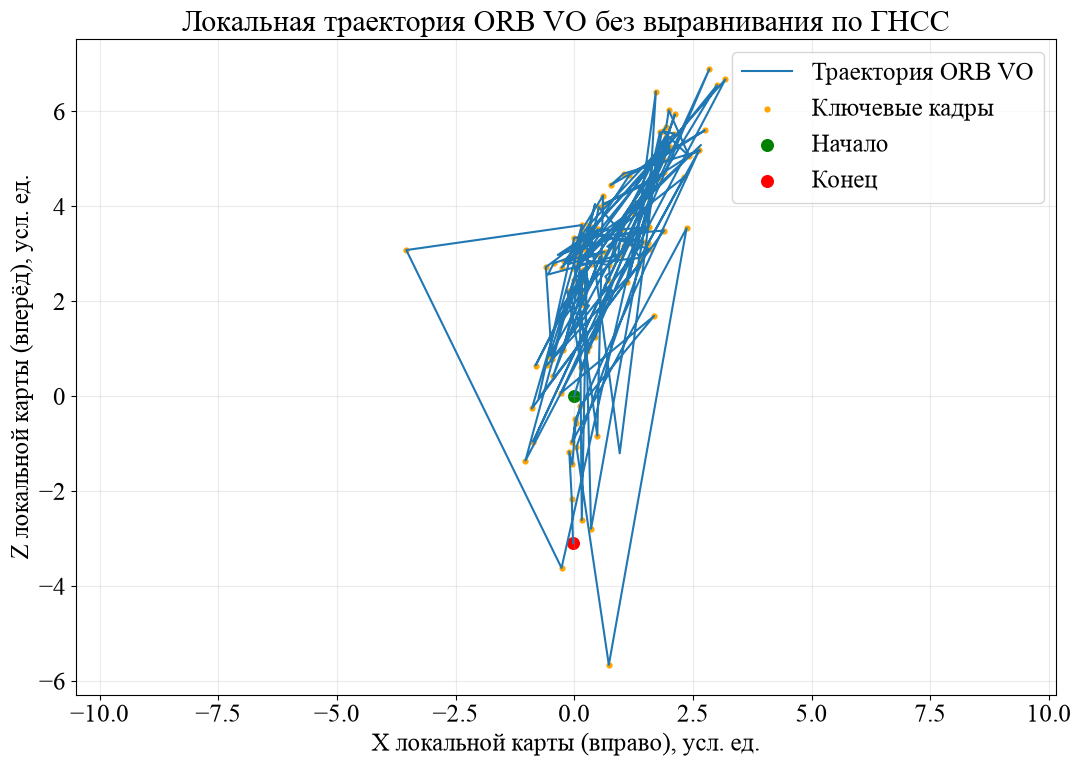

In [35]:
def rotation_to_quaternion(R):
    # Перевод матрицы поворота в кватернион с устойчивым выбором ветки по следу/диагонали.
    trace = np.trace(R)
    if trace > 0:
        s = np.sqrt(trace + 1.0) * 2
        qw = 0.25 * s
        qx, qy, qz = (R[2, 1] - R[1, 2]) / s, (R[0, 2] - R[2, 0]) / s, (R[1, 0] - R[0, 1]) / s
    else:
        index = int(np.argmax(np.diag(R)))
        if index == 0:
            s = np.sqrt(1.0 + R[0, 0] - R[1, 1] - R[2, 2]) * 2
            qw, qx = (R[2, 1] - R[1, 2]) / s, 0.25 * s
            qy, qz = (R[0, 1] + R[1, 0]) / s, (R[0, 2] + R[2, 0]) / s
        elif index == 1:
            s = np.sqrt(1.0 + R[1, 1] - R[0, 0] - R[2, 2]) * 2
            qw, qy = (R[0, 2] - R[2, 0]) / s, 0.25 * s
            qx, qz = (R[0, 1] + R[1, 0]) / s, (R[1, 2] + R[2, 1]) / s
        else:
            s = np.sqrt(1.0 + R[2, 2] - R[0, 0] - R[1, 1]) * 2
            qw, qz = (R[1, 0] - R[0, 1]) / s, 0.25 * s
            qx, qy = (R[0, 2] + R[2, 0]) / s, (R[1, 2] + R[2, 1]) / s
    quaternion = np.array([qx, qy, qz, qw])
    return quaternion / np.linalg.norm(quaternion)

def pose_to_tum(index, pose):
    # TUM хранит camera→world: центр камеры и ориентацию, обратную world→camera.
    R_wc = pose[:3, :3].T
    center = -R_wc @ pose[:3, 3]
    quaternion = rotation_to_quaternion(R_wc)
    return [timestamps[index], *center, *quaternion]

with (RESULTS_DIR / 'orb_tum.txt').open('w', encoding='utf-8') as stream:
    for index in sorted(successful_poses):
        stream.write(' '.join(f'{value:.9f}' for value in pose_to_tum(index, successful_poses[index])) + '\n')
with (RESULTS_DIR / 'orb_metrics.csv').open('w', newline='', encoding='utf-8') as stream:
    writer = csv.DictWriter(stream, fieldnames=list(diagnostics[0]))
    writer.writeheader()
    writer.writerows(diagnostics)

centers = np.array([-pose[:3, :3].T @ pose[:3, 3] for _, pose in sorted(successful_poses.items())])
keyframe_centers = np.array([-successful_poses[i][:3, :3].T @ successful_poses[i][:3, 3]
                             for i in keyframe_indices if i in successful_poses])
figure, axis = plt.subplots(figsize=(11, 8))
axis.plot(centers[:, 0], centers[:, 2], linewidth=1.5, label='Траектория ORB VO')
axis.scatter(keyframe_centers[:, 0], keyframe_centers[:, 2], s=12, color='orange', label='Ключевые кадры')
axis.scatter(*centers[0, [0, 2]], color='green', s=70, label='Начало')
axis.scatter(*centers[-1, [0, 2]], color='red', s=70, label='Конец')
axis.set(xlabel='X локальной карты (вправо), усл. ед.',
         ylabel='Z локальной карты (вперёд), усл. ед.',
         title='Локальная траектория ORB VO без выравнивания по ГНСС')
axis.axis('equal')
axis.grid(alpha=0.25)
axis.legend()
figure.tight_layout()
figure.savefig(RESULTS_DIR / 'orb_trajectory_local.png', dpi=200, bbox_inches='tight')
print(f'Сохранено {len(successful_poses)} TUM-поз и {len(diagnostics)} строк диагностики')

## 7. Проверка и выводы

Маска должна исключать неподвижные элементы, RANSAC и PnP — сохранять достаточно inliers, репроекция — оставаться малой, а трекинг — покрывать последовательность. Малое покрытие важнее обманчиво гладкой короткой траектории. Сохранённые TUM/CSV/JSON используются далее для повторного сравнения с прямым методом и ГНСС.

In [36]:
tracked_rows = [row for row in diagnostics if row['status'] == 'tracked']
runtimes = np.array([row['runtime_s'] for row in tracked_rows])
pnp_values = np.array([row['pnp_inliers'] for row in tracked_rows])
reprojection_values = np.array([row['median_reprojection_px'] for row in tracked_rows])
summary = {
    'algorithm': 'educational_orb_vo_not_full_orb_slam2',
    'frames': len(image_paths), 'valid_poses': len(successful_poses),
    'completeness': len(successful_poses) / len(image_paths),
    'lost_frames': lost_frames, 'keyframes': len(keyframe_indices), 'map_points': len(map_points),
    'mask_excluded_percent': float(excluded_percent),
    'initialization_essential_inliers': essential_inliers,
    'initialization_matches': len(initialization_matches),
    'median_pnp_inliers': float(np.median(pnp_values)) if len(pnp_values) else None,
    'median_reprojection_px': float(np.nanmedian(reprojection_values)) if len(reprojection_values) else None,
    'runtime_mean_s': float(runtimes.mean()) if len(runtimes) else None,
    'runtime_p95_s': float(np.percentile(runtimes, 95)) if len(runtimes) else None,
    'mono_scale_constant': MONO_SCALE_CONSTANT,
    'calibration_warning': 'Temporary fx/fy estimate; not a checkerboard calibration',
}
(RESULTS_DIR / 'orb_summary.json').write_text(json.dumps(summary, ensure_ascii=False, indent=2), encoding='utf-8')
print(json.dumps(summary, ensure_ascii=False, indent=2))
if summary['completeness'] < 0.95:
    print('ВЫВОД: есть потерянные кадры; ATE относится только к сохранённым позам.')
if summary['median_reprojection_px'] is not None and summary['median_reprojection_px'] < 1.0:
    print('ВЫВОД: медианная репроекция <1 px, но временная калибровка и дрейф масштаба остаются ограничениями.')

NameError: name 'lost_frames' is not defined